In [1]:
import os
import numpy as np
import pandas as pd
import timm
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
import torch.optim as optim
from torchvision.utils import make_grid
from torchvision import transforms
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from PIL import Image
import matplotlib.pyplot as plt
import timeit
from tqdm import tqdm
import seaborn as sns
import altair as alt

import warnings
warnings.filterwarnings("ignore")

os.environ['CUDA_LAUNCH_BLOCKING'] = '1'
os.environ['TORCH_USE_CUDA_DSA'] = '1'

In [2]:
class CustomImageDataset(Dataset):
    def __init__(self, root_dir, dataset_type, transform=None):
        self.root_dir = root_dir
        self.dataset_type = dataset_type
        self.transform = transform
        self.images = []
        self.labels = []

        for sub_dataset in os.listdir(root_dir):
            sub_dataset_path = os.path.join(root_dir, sub_dataset)
            for nasted_dir in os.listdir(sub_dataset_path):
                nasted_dir_path = os.path.join(sub_dataset_path, nasted_dir)
                dataset_type_dir = os.path.join(nasted_dir_path, dataset_type)
                for label in os.listdir(dataset_type_dir):
                    label_folder = os.path.join(dataset_type_dir, label)
                    for image_name in os.listdir(label_folder):
                        image_path = os.path.join(label_folder, image_name)
                        self.images.append(image_path)
                        self.labels.append(label)

        self.label_encoder = LabelEncoder()
        self.encoded_labels = self.label_encoder.fit_transform(self.labels)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        label = self.encoded_labels[idx]

        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

In [3]:
# train_transforms = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor(),
# ])

# test_transforms = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor(),
# ])

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

In [4]:
dataset_path = '/kaggle/input/real-and-fake-images-dataset-for-image-forensics'

train_dataset = CustomImageDataset(root_dir=dataset_path, dataset_type="train", transform=transform)
val_dataset = CustomImageDataset(root_dir=dataset_path, dataset_type="validation", transform=transform)
test_dataset = CustomImageDataset(root_dir=dataset_path, dataset_type="test", transform=transform)

print(f"Total Training Dataset: {len(train_dataset)}")
print(f"Total Validation Dataset: {len(val_dataset)}")
print(f"Total Test Dataset: {len(test_dataset)}")

print(f"Total image samples {len(train_dataset)+len(val_dataset)+len(test_dataset)}")


Total Training Dataset: 160002
Total Validation Dataset: 49428
Total Test Dataset: 20905
Total image samples 230335


In [5]:
# images, labels = [], []

# for i in range(50):
#     image, label = train_dataset[i]
#     images.append(image)
#     labels.append(label)
    
# image_grid = make_grid(images, nrow=10, padding=5, pad_value=1)
# np_image_grid = image_grid.permute(1, 2, 0).cpu().numpy()

# plt.figure(figsize=(15, 10))
# plt.imshow(np_image_grid)
# plt.axis("off")
# plt.title("Training Dataset Images")
# plt.show()

In [6]:
# images, labels = [], []

# for i in range(50):
#     image, label = test_dataset[i]
#     images.append(image)
#     labels.append(label)
    
# image_grid = make_grid(images, nrow=10, padding=5, pad_value=1)
# np_image_grid = image_grid.permute(1, 2, 0).cpu().numpy()

# plt.figure(figsize=(15, 10))
# plt.imshow(np_image_grid)
# plt.axis("off")
# plt.title("Test Dataset Images")
# plt.show()

In [7]:
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

In [8]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


# Initialize and configure the training process


In [9]:
from transformers import ViTForImageClassification

model = ViTForImageClassification.from_pretrained(
    'google/vit-base-patch16-224',
    num_labels=2,
    ignore_mismatched_sizes=True
).to(device)

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224 and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([2]) in the model instantiated
- classifier.weight: found shape torch.Size([1000, 768]) in the checkpoint and torch.Size([2, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [10]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
epochs = 10

loss_dict = {"epoch": [], "train": [], "val": []}
accuracy_dict = {"epoch": [], "train": [], "val": []}

# Define early stopping parameters
patience = 5  
min_delta = 0.001 

best_val_accuracy = 0
counter = 0
early_stop = False

# Begin the training loop


In [11]:
start = timeit.default_timer()

for epoch in range(epochs):
    if early_stop:
        print("Early stopping triggered!")
        break
    
    epoch_start = timeit.default_timer()
    
    model.train()
    train_loss = 0
    train_preds, train_labels = [], []
    
    # train_loader_tqdm = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs} - Training", leave=False)
    for batch_idx, batch in enumerate(train_loader):
        images = batch[0].to(device)
        labels = batch[1].to(device)
        
        optimizer.zero_grad()
        output = model(images).logits
        loss = criterion(output, labels)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        preds = torch.argmax(output, dim=1)
        
        train_preds.extend(preds.cpu().tolist())
        train_labels.extend(labels.cpu().tolist())
        
        train_accuracy = sum(1 for x, y in zip(train_preds, train_labels) if x == y) / len(train_labels)
        
        # train_loader_tqdm.set_postfix(train_loss=train_loss / (batch_idx + 1), 
        #                               train_accuracy=train_accuracy)
    
    train_loss /= len(train_loader)
    train_accuracy = sum(1 for x, y in zip(train_preds, train_labels) if x == y) / len(train_labels)
    
    # Validation Phase
    model.eval()
    val_loss = 0
    val_preds, val_labels = [], []
    
    # val_loader_tqdm = tqdm(val_loader, desc=f"Epoch {epoch + 1}/{epochs} - Validation", leave=False)
    with torch.no_grad():
        for batch_idx, batch in enumerate(val_loader):
            images = batch[0].to(device)
            labels = batch[1].to(device)
            
            output = model(images).logits
            loss = criterion(output, labels)
            val_loss += loss.item()
            
            preds = torch.argmax(output, dim=1)
            val_preds.extend(preds.cpu().tolist())
            val_labels.extend(labels.cpu().tolist())
            
            val_accuracy = sum(1 for x, y in zip(val_preds, val_labels) if x == y) / len(val_labels)
            
            # val_loader_tqdm.set_postfix(val_loss=val_loss / (batch_idx + 1), 
            #                             val_accuracy=val_accuracy)
    
    val_loss /= len(val_loader)
    val_accuracy = sum(1 for x, y in zip(val_preds, val_labels) if x == y) / len(val_labels)
    
    loss_dict["epoch"].append(epoch + 1)
    loss_dict["train"].append(train_loss)
    loss_dict["val"].append(val_loss)
    
    accuracy_dict["epoch"].append(epoch + 1)
    accuracy_dict["train"].append(train_accuracy)
    accuracy_dict["val"].append(val_accuracy)
    
    scheduler.step()

    if val_accuracy > best_val_accuracy + min_delta:
        best_val_accuracy = val_accuracy
        counter = 0

        # model_name = f"model_checkpoint_epoch_{epoch + 1}_accuracy_{val_accuracy:.4f}.pth"

        # torch.save({
        #     'epoch': epoch + 1,
        #     'model_state_dict': model.state_dict(),
        #     'optimizer_state_dict': optimizer.state_dict(),
        #     'loss_dict': loss_dict,
        #     'accuracy_dict': accuracy_dict,
        # }, model_name)

        # print(f"Checkpoint saved as {model_name}")

    else:
        counter += 1
        if counter >= patience:
            early_stop = True
    
    epoch_end = timeit.default_timer()
    epoch_duration = epoch_end - epoch_start
    
    print(f"Epoch {epoch + 1}/{epochs}: "
          f"Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, "
          f"Train Accuracy: {train_accuracy:.2f}%, Val Accuracy: {val_accuracy:.2f}%, "
          f"Duration: {epoch_duration / 60:.2f} min")
    
    torch.cuda.empty_cache()

stop = timeit.default_timer()
print(f"Total Training Time: {(stop - start) / 60:.2f} min")

Epoch 1/10: Train Loss: 0.1038, Val Loss: 0.0649, Train Accuracy: 0.96%, Val Accuracy: 0.98%, Duration: 89.94 min
Epoch 2/10: Train Loss: 0.0377, Val Loss: 0.0575, Train Accuracy: 0.99%, Val Accuracy: 0.98%, Duration: 67.86 min
Epoch 3/10: Train Loss: 0.0275, Val Loss: 0.1450, Train Accuracy: 0.99%, Val Accuracy: 0.96%, Duration: 67.80 min
Epoch 4/10: Train Loss: 0.0262, Val Loss: 0.0663, Train Accuracy: 0.99%, Val Accuracy: 0.98%, Duration: 67.46 min
Epoch 5/10: Train Loss: 0.0167, Val Loss: 0.0523, Train Accuracy: 0.99%, Val Accuracy: 0.98%, Duration: 67.92 min
Epoch 6/10: Train Loss: 0.0042, Val Loss: 0.0576, Train Accuracy: 1.00%, Val Accuracy: 0.99%, Duration: 70.90 min
Epoch 7/10: Train Loss: 0.0019, Val Loss: 0.0626, Train Accuracy: 1.00%, Val Accuracy: 0.99%, Duration: 69.29 min
Epoch 8/10: Train Loss: 0.0016, Val Loss: 0.0697, Train Accuracy: 1.00%, Val Accuracy: 0.99%, Duration: 68.38 min
Epoch 9/10: Train Loss: 0.0015, Val Loss: 0.0699, Train Accuracy: 1.00%, Val Accuracy: 0

In [12]:
model_name = f"model_checkpoint_epoch_{epoch + 1}_accuracy_{val_accuracy:.4f}.pth"
torch.save({
    'epoch': epoch + 1,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'loss_dict': loss_dict,
    'accuracy_dict': accuracy_dict,
}, model_name)

print(f"Checkpoint saved as {model_name}")

Checkpoint saved as model_checkpoint_epoch_10_accuracy_0.9864.pth


In [13]:
loss_data = pd.DataFrame({
    'Epoch': loss_dict['epoch'] * 2,
    'Value': loss_dict['train'] + loss_dict['val'],
    'Type': ['Training Loss'] * len(loss_dict['epoch']) + ['Validation Loss'] * len(loss_dict['epoch'])
})

# Calculate the mean value for centering the graph
mean_loss = loss_data['Value'].mean()

# Create loss chart with centered y-axis
loss_chart = alt.Chart(loss_data).mark_line(point=True).encode(
    x=alt.X('Epoch:O', title='Epoch'),
    y=alt.Y('Value:Q', title='Loss', scale=alt.Scale(domain=[mean_loss - 0.5, mean_loss + 0.5])),
    color=alt.Color('Type:N', title='Type'),
    tooltip=['Epoch', 'Value', 'Type']
).properties(
    title="Training and Validation Loss",
    width=800,
    height=400
).interactive()

loss_chart.show()

alt.Chart(...)

In [14]:
accuracy_data = pd.DataFrame({
    'Epoch': accuracy_dict['epoch'] * 2,
    'Value': accuracy_dict['train'] + accuracy_dict['val'],
    'Type': ['Training Accuracy'] * len(accuracy_dict['epoch']) + ['Validation Accuracy'] * len(accuracy_dict['epoch'])
})

# Calculate the mean value for centering the graph
mean_accuracy = accuracy_data['Value'].mean()

# Create accuracy chart with centered y-axis
accuracy_chart = alt.Chart(accuracy_data).mark_line(point=True).encode(
    x=alt.X('Epoch:O', title='Epoch'),
    y=alt.Y('Value:Q', title='Accuracy', scale=alt.Scale(domain=[mean_accuracy - 0.1, mean_accuracy + 0.1])),
    color=alt.Color('Type:N', title='Type'),
    tooltip=['Epoch', 'Value', 'Type']
).properties(
    title="Training and Validation Accuracy",
    width=800,
    height=400
).interactive()

accuracy_chart.show()

alt.Chart(...)

# Initializing Test

In [15]:
def get_num_correct(preds, labels):
    return preds.argmax(dim=1).eq(labels).sum().item()

In [16]:
with torch.no_grad():
    test_loss = 0
    total_correct = 0
    
    all_labels = []
    all_preds = []
    
    # Get the size of the test dataset
    total_test_samples = len(test_loader.dataset)
    
    # test_loader_tqdm = tqdm(test_loader, desc="Testing", leave=True)
    for batch in test_loader:
        images = batch[0].to(device)
        labels = batch[1].to(device)

        outputs = model(images).logits
        loss = criterion(outputs, labels)
        test_loss += loss.item()

        total_correct += get_num_correct(outputs, labels)
        
        # Append labels and predictions to the lists
        all_labels.extend(labels.cpu().numpy())
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())

        # Update tqdm with current loss and accuracy
        # test_loader_tqdm.set_postfix(
        #     test_loss=f"{test_loss / (test_loader_tqdm.n + 1):.3f}",
        #     test_accuracy=f"{(total_correct / total_test_samples):.3f}"
        # )

    # Calculate average loss and accuracy
    test_loss /= len(test_loader)
    test_accuracy = total_correct / len(test_loader.dataset)

# Output the final results
print(f"Test Loss: {test_loss:.2f}, Test Accuracy: {test_accuracy:.2f}%, Total Correct: {total_correct}")

Test Loss: 0.22, Test Accuracy: 0.96%, Total Correct: 20087


In [17]:
# Define the class labels based on your encoding (fake = 0, real = 1)
class_labels = ['Fake', 'Real']

# Generate confusion matrix
cm = confusion_matrix(all_labels, all_preds, labels=[0, 1])

# Convert confusion matrix to DataFrame for Altair
cm_df = pd.DataFrame(cm, columns=class_labels, index=class_labels)

# Reshape the confusion matrix DataFrame for Altair
cm_melted = cm_df.reset_index().melt(id_vars='index', var_name='Predicted', value_name='Count')
cm_melted = cm_melted.rename(columns={'index': 'True'})

# Create confusion matrix heatmap using Altair with a larger size
confusion_matrix_chart = alt.Chart(cm_melted).mark_rect().encode(
    x='Predicted:N',
    y='True:N',
    color='Count:Q',
    tooltip=['True', 'Predicted', 'Count']
).properties(
    title='Confusion Matrix',
    width=600,  # Increase width
    height=500  # Increase height
)

# Add annotations inside the heatmap
text_annotations = alt.Chart(cm_melted).mark_text().encode(
    x='Predicted:N',
    y='True:N',
    text='Count:Q',
    color=alt.value('black')  # Set text color to black
)

# Combine the heatmap and the annotations
final_chart = confusion_matrix_chart + text_annotations

final_chart.show()


alt.LayerChart(...)

In [18]:
report = classification_report(all_labels, all_preds, target_names=['fake','real'], output_dict=True)
df_report = pd.DataFrame(report).transpose()

df_report

,precision,recall,f1-score,support
fake,0.937817,0.987514,0.962024,10492.000000
real,0.986710,0.934025,0.959645,10413.000000
accuracy,0.960871,0.960871,0.960871,0.960871
macro avg,0.962263,0.960770,0.960834,20905.000000
weighted avg,0.962171,0.960871,0.960839,20905.000000


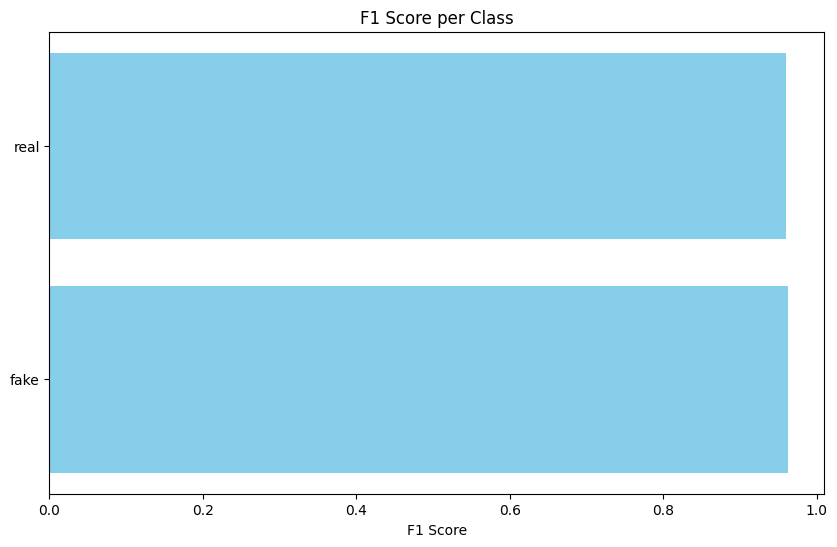

In [19]:
# Plot the F1 scores for each class
f1_scores = df_report['f1-score'][:-3]  # Exclude the 'average' row
classes = df_report.index[:-3]  # Exclude the 'average' row

plt.figure(figsize=(10, 6))
plt.barh(classes, f1_scores, color='skyblue')
plt.xlabel('F1 Score')
plt.title('F1 Score per Class')
plt.show()
